# Adaptive Application-Layer Compression — Evaluation Notebook

Analyses the adaptive-compression campaign in isolation (no comparison to baseline here — see `comparison.ipynb`).

**Input:** `results_traffic_class_compress_eval/tidy/*.csv`  
**Run:** after `extract_kpis.py`

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

TIDY = Path('results_traffic_class_compress_eval/tidy')

CLASS_ORDER = ['periodic1', 'periodic2', 'periodic3', 'aperiodic1', 'aperiodic2']
CLASS_LABELS = {
    'periodic1':  'P1\n200B·10Hz',
    'periodic2':  'P2\n1kB·10Hz',
    'periodic3':  'P3\n45kB·1Hz',
    'aperiodic1': 'A1\n1kB·aperiodic',
    'aperiodic2': 'A2\n20kB·aperiodic',
}
CODEC_NAMES  = {0: 'NONE', 1: 'LZ4', 2: 'ZSTD_L1', 3: 'ZSTD_L3'}
CODEC_COLORS = {0: '#aaaaaa', 1: '#4daf4a', 2: '#377eb8', 3: '#e41a1c'}

def load(name):
    p = TIDY / name
    return pd.read_csv(p) if p.exists() else pd.DataFrame()

rx   = load('per_rx_kpis.csv')
ts   = load('time_series.csv')
ru   = load('resource_usage.csv')
harq = load('harq_stats.csv')
comp = load('compression_log.csv')
frag = load('rlc_frag.csv')
pdb  = load('pdb_violations.csv')

# Normalise scheme column: in compression tidy, scheme is the mode dir name
# Keep only the 'adaptive' rows if multiple modes are present
if 'scheme' in rx.columns and rx.scheme.nunique() > 1:
    print('Available schemes:', rx.scheme.unique())
    rx   = rx[rx.scheme == 'adaptive'].copy()
    harq = harq[harq.scheme == 'adaptive'].copy() if 'scheme' in harq.columns else harq

classes = [c for c in CLASS_ORDER if c in rx.trafficClass.unique()]
print(f'Classes: {classes}')
print(f'RX rows: {len(rx):,}  |  comp-log rows: {len(comp):,}  |  frag rows: {len(frag):,}')

Classes: ['periodic1', 'periodic2', 'periodic3', 'aperiodic1', 'aperiodic2']
RX rows: 800  |  comp-log rows: 703,384  |  frag rows: 245,131


## 2. Per-RX distributions: PRR, PIR, throughput

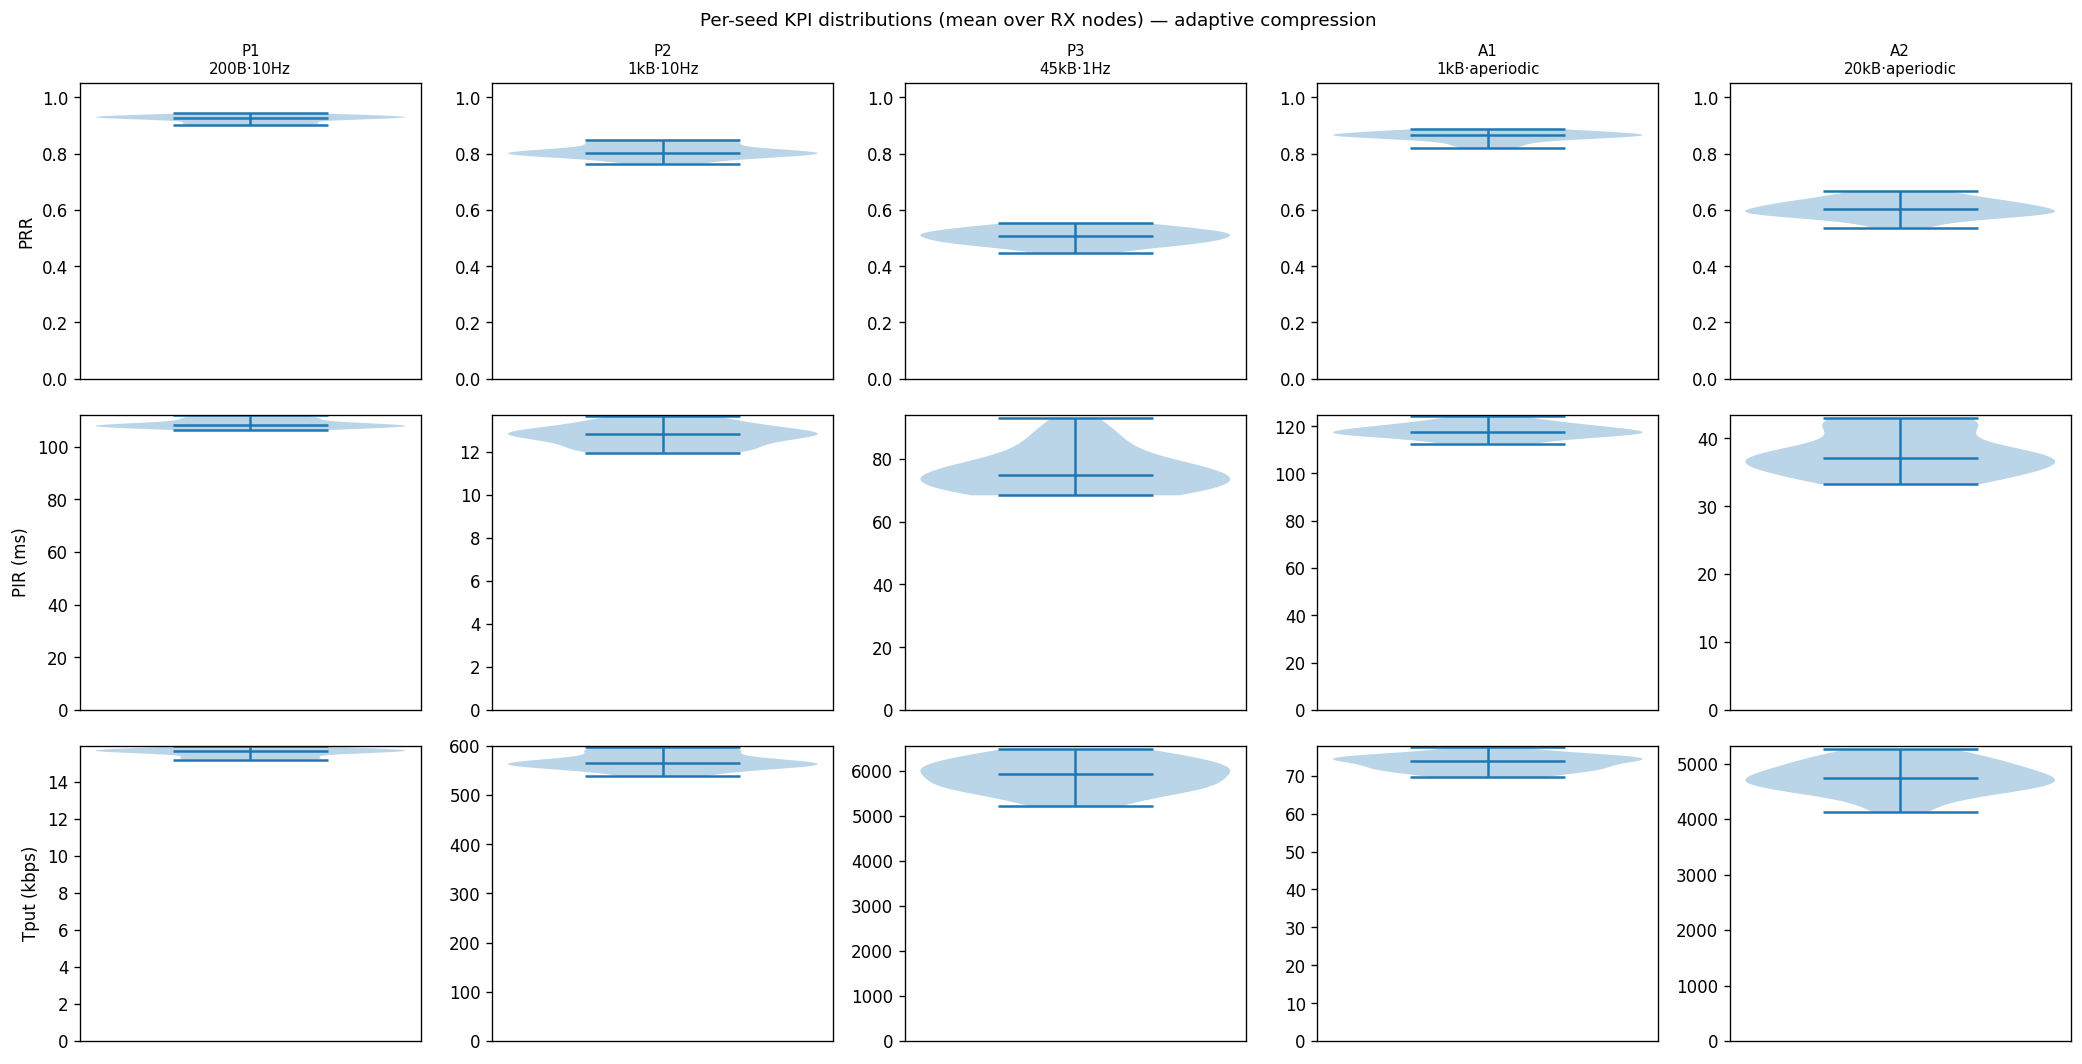

In [2]:
metrics = [
    ('prr',       'PRR',         (0, 1.05)),
    ('pir_ms',    'PIR (ms)',    (0, None)),
    ('tput_kbps', 'Tput (kbps)', (0, None)),
]
fig, axes = plt.subplots(len(metrics), len(classes),
                          figsize=(3.5*len(classes), 3*len(metrics)))
if len(classes) == 1:
    axes = axes.reshape(-1, 1)

for ci, cls in enumerate(classes):
    sub = rx[rx.trafficClass == cls]
    for mi, (col, label, ylim) in enumerate(metrics):
        ax = axes[mi, ci]
        vals = sub.groupby('seed')[col].mean().dropna()
        if vals.empty:
            ax.set_visible(False); continue
        ax.violinplot([vals], showmedians=True)
        ax.set_xticks([])
        ax.set_ylabel(label if ci == 0 else '')
        if ylim[0] is not None: ax.set_ylim(bottom=ylim[0])
        if ylim[1] is not None: ax.set_ylim(top=ylim[1])
        if mi == 0: ax.set_title(CLASS_LABELS.get(cls, cls), fontsize=9)

fig.suptitle('Per-seed KPI distributions (mean over RX nodes) — adaptive compression', fontsize=11)
fig.tight_layout()
plt.show()

## 3. PRR vs distance

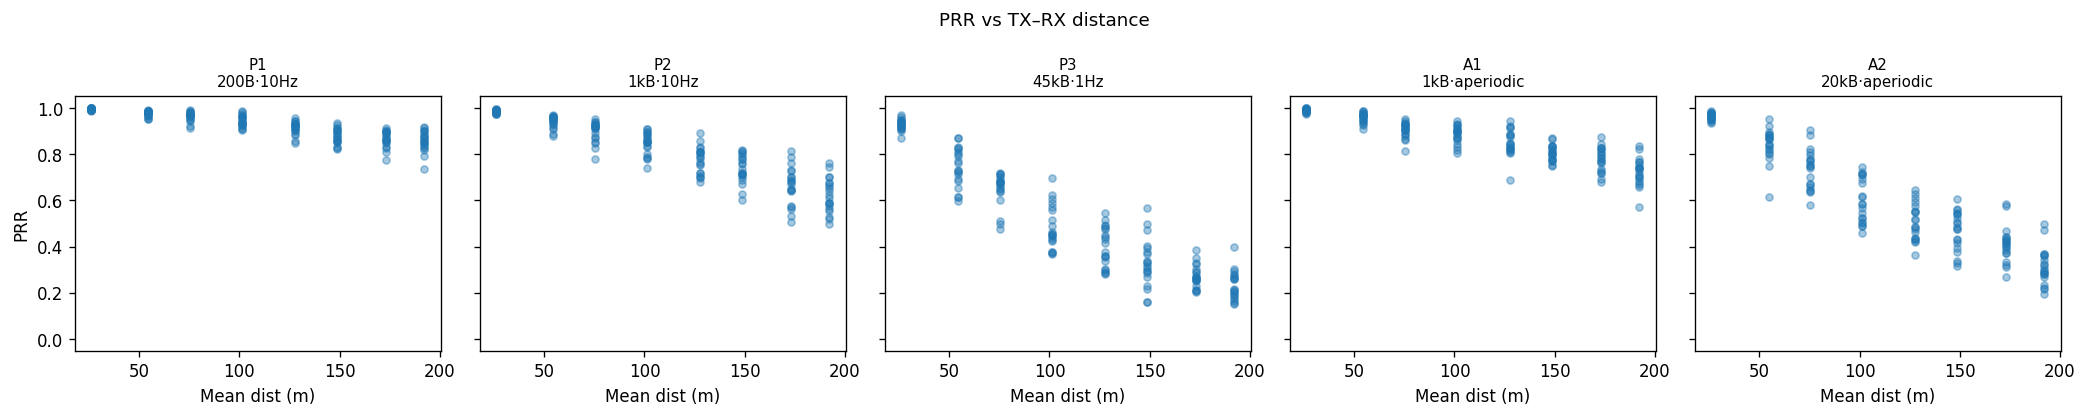

In [3]:
fig, axes = plt.subplots(1, len(classes), figsize=(3.5*len(classes), 3.5), sharey=True)
if len(classes) == 1: axes = [axes]
for ax, cls in zip(axes, classes):
    sub = rx[rx.trafficClass == cls].groupby(['seed','rx_node_id'])[['mean_dist_m','prr']].mean().reset_index()
    ax.scatter(sub.mean_dist_m, sub.prr, alpha=0.4, s=18)
    ax.set_xlabel('Mean dist (m)')
    ax.set_title(CLASS_LABELS.get(cls, cls), fontsize=9)
    ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel('PRR')
fig.suptitle('PRR vs TX–RX distance', fontsize=11)
fig.tight_layout()
plt.show()

## 4. Time-series PRR per class

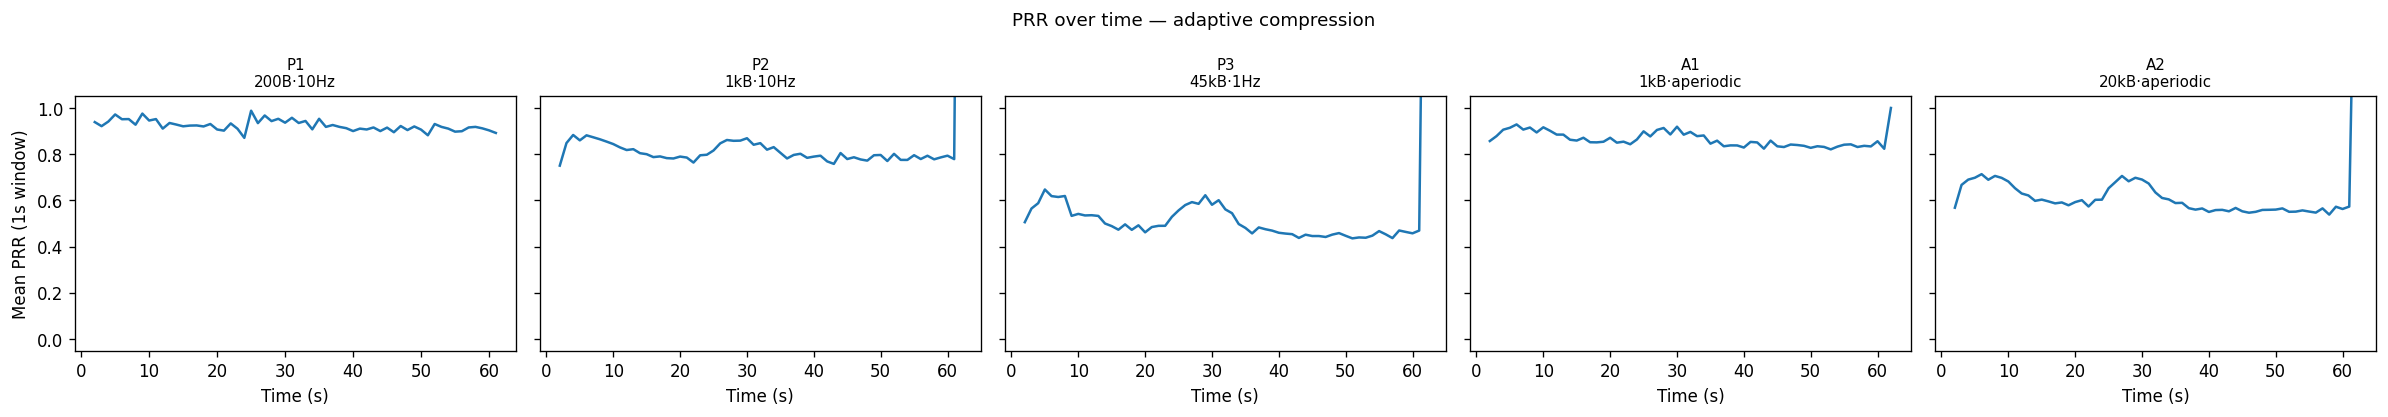

In [4]:
if ts.empty:
    print('No time_series.csv')
else:
    fig, axes = plt.subplots(1, len(classes), figsize=(4*len(classes), 3.5), sharey=True)
    if len(classes) == 1: axes = [axes]
    for ax, cls in zip(axes, classes):
        sub = ts[ts.trafficClass == cls]
        if 'scheme' in sub.columns:
            sub = sub[sub.scheme == 'adaptive']
        mean_prr = sub.groupby('t_bin_s')['prr_window'].mean()
        ax.plot(mean_prr.index, mean_prr.values)
        ax.set_xlabel('Time (s)')
        ax.set_ylim(-0.05, 1.05)
        ax.set_title(CLASS_LABELS.get(cls, cls), fontsize=9)
    axes[0].set_ylabel('Mean PRR (1s window)')
    fig.suptitle('PRR over time — adaptive compression', fontsize=11)
    fig.tight_layout()
    plt.show()

## 5. Resource usage

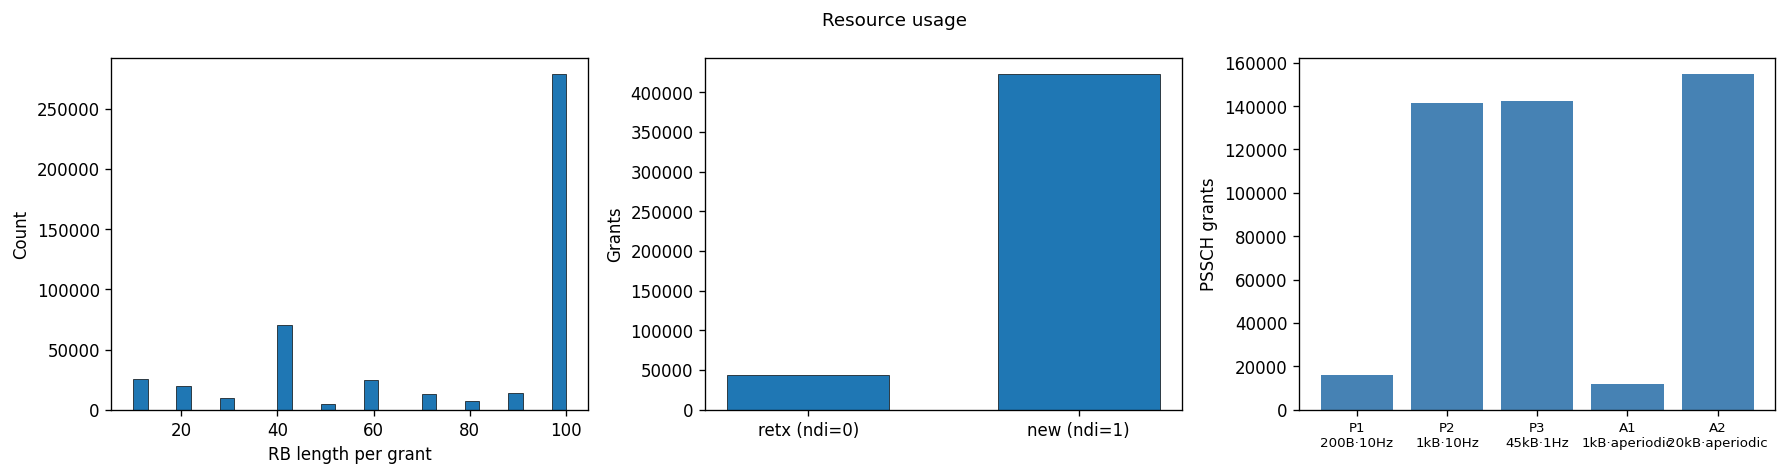

In [5]:
if ru.empty:
    print('No resource_usage.csv')
else:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].hist(ru.rbLen, bins=30, edgecolor='k', linewidth=0.4)
    axes[0].set_xlabel('RB length per grant')
    axes[0].set_ylabel('Count')

    axes[1].hist(ru.ndi, bins=[-0.5,0.5,1.5], edgecolor='k', linewidth=0.4, rwidth=0.6)
    axes[1].set_xticks([0, 1])
    axes[1].set_xticklabels(['retx (ndi=0)', 'new (ndi=1)'])
    axes[1].set_ylabel('Grants')

    if 'trafficClass' in ru.columns:
        by_cls = ru.groupby('trafficClass').size().reindex(CLASS_ORDER)
        axes[2].bar(range(len(classes)), by_cls.reindex(classes), color='steelblue')
        axes[2].set_xticks(range(len(classes)))
        axes[2].set_xticklabels([CLASS_LABELS.get(c,c) for c in classes], fontsize=8)
        axes[2].set_ylabel('PSSCH grants')
    else:
        axes[2].set_visible(False)

    fig.suptitle('Resource usage', fontsize=11)
    fig.tight_layout()
    plt.show()

## 6. HARQ statistics

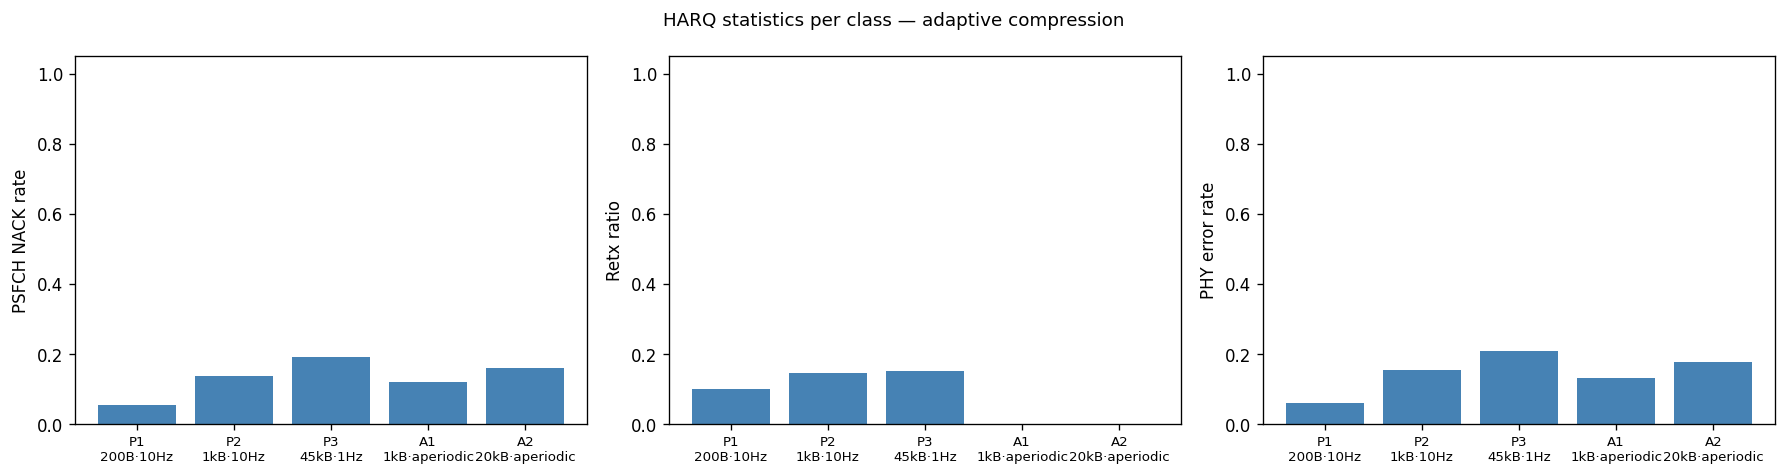

In [6]:
if harq.empty:
    print('No harq_stats.csv')
else:
    metrics_h = [
        ('nack_rate',    'PSFCH NACK rate'),
        ('retx_ratio',   'Retx ratio'),
        ('phy_err_rate', 'PHY error rate'),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    x = np.arange(len(classes))
    for ax, (col, label) in zip(axes, metrics_h):
        vals = harq.groupby('trafficClass')[col].mean().reindex(classes)
        ax.bar(x, vals, color='steelblue')
        ax.set_xticks(x)
        ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes], fontsize=8)
        ax.set_ylabel(label)
        ax.set_ylim(0, 1.05)
    fig.suptitle('HARQ statistics per class — adaptive compression', fontsize=11)
    fig.tight_layout()
    plt.show()

## 6b. Compression behaviour

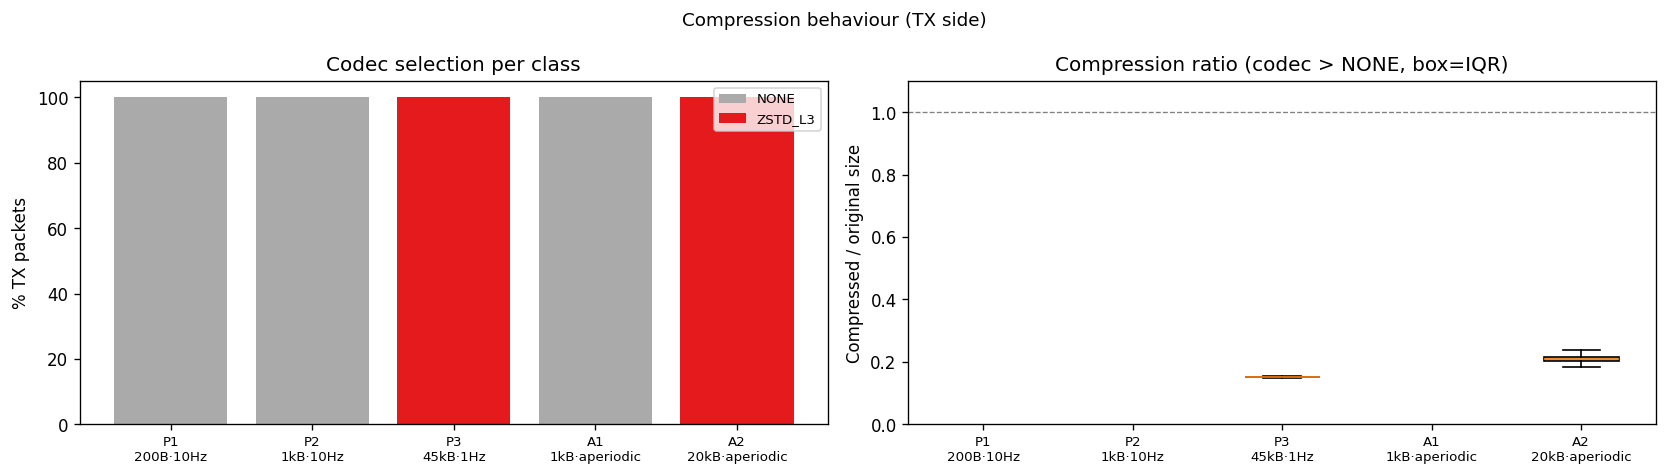

              ratio                   encodeUs                  
               mean median <lambda_0>     mean median <lambda_0>
trafficClass                                                    
aperiodic2    0.210  0.210      0.228  264.216  254.0      409.0
periodic3     0.152  0.152      0.154  524.016  494.0      824.0


In [7]:
if comp.empty:
    print('No compression_log.csv')
else:
    tx = comp[comp.txRx == 'tx']
    # Codec mix per class (stacked bar)
    counts = tx.groupby(['trafficClass','codec']).size().unstack(fill_value=0)
    pct    = counts.divide(counts.sum(axis=1), axis=0) * 100
    cls_here = [c for c in CLASS_ORDER if c in pct.index]
    pct = pct.reindex(cls_here)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    bottom = np.zeros(len(cls_here))
    for codec in sorted(pct.columns):
        vals = pct[codec].values
        axes[0].bar(range(len(cls_here)), vals, bottom=bottom,
                    label=CODEC_NAMES.get(int(codec), str(codec)),
                    color=CODEC_COLORS.get(int(codec), '#888'))
        bottom += vals
    axes[0].set_xticks(range(len(cls_here)))
    axes[0].set_xticklabels([CLASS_LABELS.get(c,c) for c in cls_here], fontsize=8)
    axes[0].set_ylabel('% TX packets')
    axes[0].set_ylim(0, 105)
    axes[0].legend(fontsize=8)
    axes[0].set_title('Codec selection per class')

    # Compression ratio box-plot per class (codec > 0 only)
    tx_comp = tx[tx.codec > 0].copy()
    if 'ratio' not in tx_comp.columns:
        tx_comp['ratio'] = tx_comp['compSize'] / tx_comp['origSize'].clip(lower=1)
    data = [tx_comp[tx_comp.trafficClass == c]['ratio'].dropna().values for c in cls_here]
    # Ensure at least 2 elements for matplotlib stats; pad singletons
    data_safe = [d if len(d) >= 2 else (np.array([d[0], d[0]]) if len(d) == 1 else np.array([np.nan, np.nan])) for d in data]
    # Use boxplot (robust to small N) instead of violin
    bp = axes[1].boxplot(data_safe, positions=range(len(cls_here)), showfliers=False, patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#aec6e8')
    axes[1].set_xticks(range(len(cls_here)))
    axes[1].set_xticklabels([CLASS_LABELS.get(c,c) for c in cls_here], fontsize=8)
    axes[1].set_ylabel('Compressed / original size')
    axes[1].set_ylim(0, 1.1)
    axes[1].axhline(1.0, ls='--', color='gray', lw=0.8)
    axes[1].set_title('Compression ratio (codec > NONE, box=IQR)')

    fig.suptitle('Compression behaviour (TX side)', fontsize=11)
    fig.tight_layout()
    plt.show()

    # Summary stats
    print(tx_comp.groupby('trafficClass')[['ratio','encodeUs']].agg(['mean','median',lambda x: x.quantile(0.95)]).round(3))

## 6c. Fragmentation impact

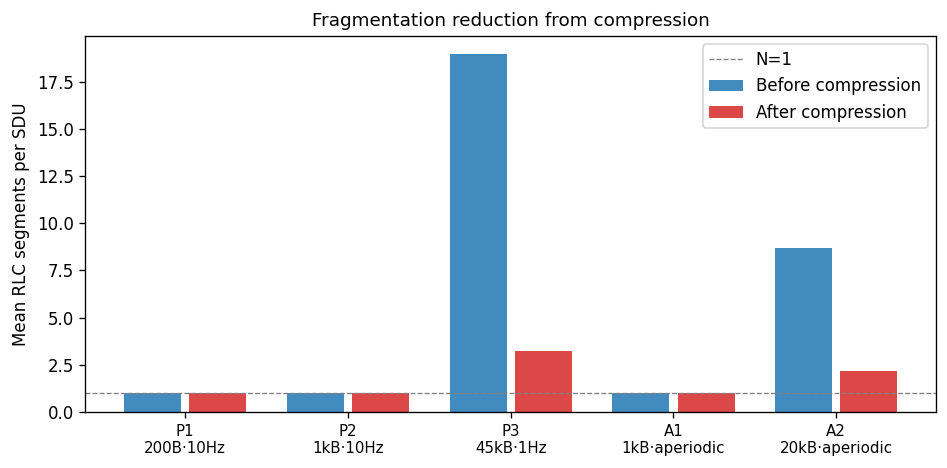

                  N_pre    N_post
trafficClass                     
periodic1      1.000000  1.000000
periodic2      1.000000  1.000000
periodic3     18.967784  3.245448
aperiodic1     1.000000  1.000000
aperiodic2     8.663962  2.171088


In [8]:
if frag.empty or 'nSegmentsPre' not in frag.columns:
    print('No rlc_frag.csv or missing nSegmentsPre column')
else:
    cls_here = [c for c in CLASS_ORDER if c in frag.trafficClass.unique()]
    pre  = frag.groupby('trafficClass')['nSegmentsPre'].mean().reindex(cls_here)
    post = frag.groupby('trafficClass')['nSegmentsPost'].mean().reindex(cls_here)

    x = np.arange(len(cls_here))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(x - 0.2, pre,  0.35, label='Before compression', color='#1f77b4', alpha=0.85)
    ax.bar(x + 0.2, post, 0.35, label='After compression',  color='#d62728', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in cls_here], fontsize=9)
    ax.set_ylabel('Mean RLC segments per SDU')
    ax.axhline(1.0, ls='--', color='gray', lw=0.8, label='N=1')
    ax.legend()
    ax.set_title('Fragmentation reduction from compression', fontsize=11)
    plt.tight_layout()
    plt.show()
    print(pd.DataFrame({'N_pre': pre, 'N_post': post}))

## 6d. Latency budget

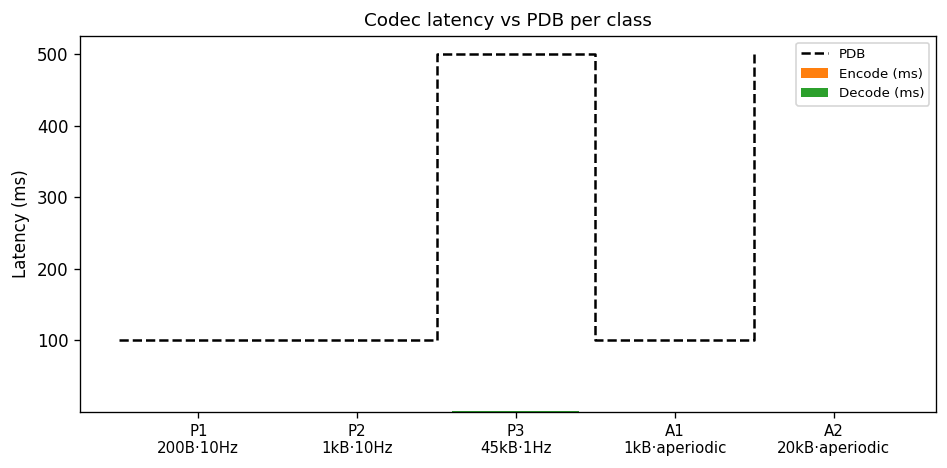

In [9]:
if comp.empty:
    print('No compression_log.csv')
else:
    PDB_MS = {'periodic1': 100, 'periodic2': 100, 'periodic3': 500,
              'aperiodic1': 100, 'aperiodic2': 500}
    tx_c = comp[comp.txRx == 'tx']
    rx_c = comp[comp.txRx == 'rx']
    cls_here = [c for c in CLASS_ORDER if c in comp.trafficClass.unique()]

    enc_mean = tx_c.groupby('trafficClass')['encodeUs'].mean().reindex(cls_here) / 1000.0
    dec_mean = rx_c.groupby('trafficClass')['decodeUs'].mean().reindex(cls_here) / 1000.0
    pdb_vals = pd.Series([PDB_MS.get(c, 100) for c in cls_here], index=cls_here)

    x = np.arange(len(cls_here))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(x, enc_mean, label='Encode (ms)', color='#ff7f0e')
    ax.bar(x, dec_mean, bottom=enc_mean, label='Decode (ms)', color='#2ca02c')
    ax.step(x - 0.5, pdb_vals.values, where='post', color='k', lw=1.5, ls='--', label='PDB')
    ax.set_xticks(x)
    ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in cls_here], fontsize=9)
    ax.set_ylabel('Latency (ms)')
    ax.legend(fontsize=8)
    ax.set_title('Codec latency vs PDB per class', fontsize=11)
    plt.tight_layout()
    plt.show()

## 6e. PDB violation rate

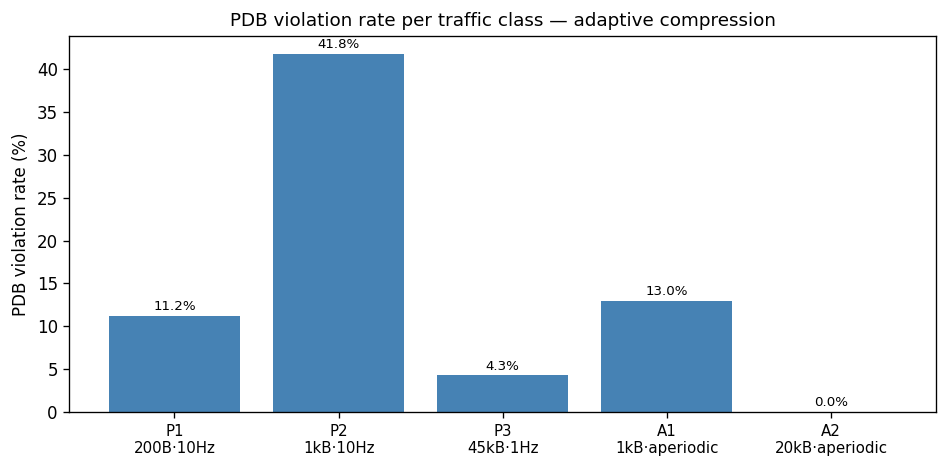

In [10]:
if pdb.empty:
    print('No pdb_violations.csv')
else:
    cls_here = [c for c in CLASS_ORDER if c in pdb.trafficClass.unique()]
    mean_viol = pdb.groupby('trafficClass')['viol_rate'].mean().reindex(cls_here) * 100

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(range(len(cls_here)), mean_viol, color='steelblue')
    ax.set_xticks(range(len(cls_here)))
    ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in cls_here], fontsize=9)
    ax.set_ylabel('PDB violation rate (%)')
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%',
                ha='center', va='bottom', fontsize=8)
    ax.set_title('PDB violation rate per traffic class — adaptive compression', fontsize=11)
    plt.tight_layout()
    plt.show()

## 7. Summary table

In [11]:
rows = []
for cls in classes:
    sub = rx[rx.trafficClass == cls]
    per_seed = sub.groupby(['seed','rx_node_id'])['prr'].mean()
    prr_mean  = sub.groupby('seed')['prr'].mean().mean()
    prr_worst = per_seed.groupby('rx_node_id').mean().min()
    prr_p5    = per_seed.quantile(0.05)
    pir_p95   = sub.pir_ms.quantile(0.95)
    tput      = sub.tput_kbps.mean()

    comp_sub  = comp[(comp.trafficClass == cls) & (comp.txRx == 'tx') & (comp.codec > 0)] if not comp.empty else pd.DataFrame()
    if 'ratio' not in comp_sub.columns and not comp_sub.empty:
        comp_sub = comp_sub.copy()
        comp_sub['ratio'] = comp_sub['compSize'] / comp_sub['origSize'].clip(lower=1)
    ratio_med = comp_sub.ratio.median() if not comp_sub.empty else float('nan')
    enc_mean  = comp_sub.encodeUs.mean() if not comp_sub.empty else float('nan')

    frag_sub = frag[frag.trafficClass == cls] if not frag.empty else pd.DataFrame()
    n_pre  = frag_sub.nSegmentsPre.mean()  if 'nSegmentsPre'  in frag_sub.columns and not frag_sub.empty else float('nan')
    n_post = frag_sub.nSegmentsPost.mean() if 'nSegmentsPost' in frag_sub.columns and not frag_sub.empty else float('nan')

    rows.append({
        'Class':        cls,
        'PRR mean':     f'{prr_mean:.3f}',
        'PRR worst-RX': f'{prr_worst:.3f}',
        'PRR p5 RX':    f'{prr_p5:.3f}',
        'PIR p95 (ms)': f'{pir_p95:.1f}' if not np.isnan(pir_p95) else '—',
        'Tput (kbps)':  f'{tput:.1f}',
        'Ratio med':    f'{ratio_med:.2f}' if not np.isnan(ratio_med) else '—',
        'Enc µs':       f'{enc_mean:.1f}'  if not np.isnan(enc_mean)  else '—',
        'N-seg pre':    f'{n_pre:.2f}'     if not np.isnan(n_pre)    else '—',
        'N-seg post':   f'{n_post:.2f}'    if not np.isnan(n_post)   else '—',
    })

pd.set_option('display.max_columns', 20)
pd.DataFrame(rows)

,Class,PRR mean,PRR worst-RX,PRR p5 RX,PIR p95 (ms),Tput (kbps),Ratio med,Enc µs,N-seg pre,N-seg post
0,periodic1,0.925,0.858,0.826,120.7,15.6,—,—,1.00,1.00
1,periodic2,0.809,0.623,0.572,17.5,568.6,—,—,1.00,1.00
2,periodic3,0.505,0.233,0.195,152.6,5901.7,0.15,524.0,18.97,3.25
3,aperiodic1,0.862,0.724,0.696,143.4,73.5,—,—,1.00,1.00
4,aperiodic2,0.605,0.314,0.287,67.0,4749.4,0.21,264.2,8.66,2.17


## Interpretation hints

- **aperiodic2 / periodic3**: these are the target classes. Post-compression `N-seg post` ≈ 1 confirms fragmentation elimination. PRR should increase substantially vs the fixed-MCS=14 baseline (see `comparison.ipynb`).
- **periodic1 / periodic2 / aperiodic1**: payload already fits in one TB → codec should be NONE for most packets. If `Ratio med` is shown, it means the estimator incorrectly triggered compression.
- **PDB violation rate**: should remain near zero for classes with PDB=100ms, since codec latency (encode+decode) is measured in tens of µs.
- **Codec selection**: the adaptive controller should choose ZSTD_L3 or ZSTD_L1 for large-payload classes based on N_est, NACK rate, and distance signals.